(sec-12-1)=
# 12.1 Typical Noises in the ECG

An ECG recorded during everyday activity often looks quite different from a clean teaching example. The baseline drifts, muscle activity adds rapid fluctuations, and electrode movement can produce large deflections. Before choosing a method to reduce these disturbances, I want to understand what each one looks like and how it overlaps with the ECG.

We will start with a relatively clean reference segment, examine common noise types, and add recorded noise at controlled levels. That gives us a way to compare methods later. I use *clean reference* as a practical label here; a real recording still contains measurement noise and is not a perfect noise-free ground truth.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
rng = np.random.default_rng(42)

(sec-12-1-1)=
## 12.1.1 The Clean ECG and Where Its Energy Lies

### Step 1: Load a clean reference recording

Throughout this chapter I use the same five minutes of MIT-BIH Arrhythmia Database record 100 {cite:p}`moody2001,goldberger2000` as the clean reference: minutes 12 to 17 of the MLII lead, sampled at 360 Hz. Record 100 is one of the cleanest records in the database, with regular sinus rhythm and only a handful of atrial premature beats. The absolute DC level of an ECG is set by electrode offset potentials and carries no cardiac information, so we subtract the segment mean once and call the result $s[n]$.

In [2]:
fs = 360
seg_from, seg_to = 12 * 60 * fs, 17 * 60 * fs          # minutes 12 to 17
rec = wfdb.rdrecord("../data/mitdb/100", sampfrom=seg_from, sampto=seg_to, channels=[0])
ann = wfdb.rdann("../data/mitdb/100", "atr", sampfrom=seg_from, sampto=seg_to)

ecg_raw = rec.p_signal[:, 0]
s = ecg_raw - ecg_raw.mean()                          # clean, zero-mean reference (mV)
t = np.arange(s.size) / fs
is_beat = np.isin(ann.symbol, ["N", "A", "V", "F", "S", "Q"])
r_peaks = ann.sample[is_beat] - seg_from              # sample indices inside the segment

rr = np.diff(r_peaks) / fs
print(f"Segment length       : {s.size / fs:.0f} s ({s.size} samples)")
print(f"Raw mean (removed)   : {ecg_raw.mean():.3f} mV")
print(f"RMS after mean removal: {np.sqrt(np.mean(s ** 2)):.3f} mV")
print(f"Beats                : {r_peaks.size}, mean heart rate {60 / rr.mean():.1f} bpm")

Segment length       : 300 s (108000 samples)
Raw mean (removed)   : -0.300 mV
RMS after mean removal: 0.195 mV
Beats                : 375, mean heart rate 75.0 bpm


### Step 2: Separate the QRS complexes from the slower waves

A single ECG beat contains waves of very different speeds. The P and T waves are slow, rounded deflections lasting 80 to 200 ms, while the QRS complex rises and falls within about 80 to 100 ms and contains the sharpest edges of the beat. To see how this shows up in frequency, we split the signal into two parts with a smooth gate: a window of $\pm 60$ ms around each annotated R peak keeps the QRS complexes, and its complement keeps the P waves, T waves and the baseline between them. The gate uses Tukey windows so that the cut itself does not create sharp edges.

In [3]:
half = int(0.06 * fs)                                  # +-60 ms around each R peak
taper = signal.windows.tukey(2 * half, alpha=0.5)
gate = np.zeros_like(s)
for r in r_peaks:
    lo, hi = r - half, r + half
    if lo >= 0 and hi <= s.size:
        gate[lo:hi] = np.maximum(gate[lo:hi], taper)

qrs_part = s * gate
slow_part = s * (1 - gate)

### Step 3: Estimate the power spectral densities

We estimate the power spectral density (PSD) of the whole ECG and of the two parts with Welch's method ([Section 7.3](../ch12_spectral_estimation/index.md)), using 16 s Hann windows with 50 % overlap. The frequency resolution is $1/16 = 0.0625$ Hz, fine enough to resolve the heart-rate harmonics. As a compact description of each spectrum, we also compute the frequency below which 90 % of the power lies.

In [4]:
def welch_psd(x, fs, seg_seconds=16):
    """Welch PSD estimate (mV^2/Hz) with Hann windows of seg_seconds length and 50 % overlap."""
    return signal.welch(x - x.mean(), fs=fs, nperseg=int(seg_seconds * fs))


def f_percent(f, S, p=90):
    """Frequency below which p percent of the PSD power lies."""
    cum = np.cumsum(S) / S.sum()
    return f[np.searchsorted(cum, p / 100)]


f, S_ecg = welch_psd(s, fs)
_, S_qrs = welch_psd(qrs_part, fs)
_, S_slow = welch_psd(slow_part, fs)

for name, S in [("whole ECG", S_ecg), ("QRS gates", S_qrs), ("P, T and baseline", S_slow)]:
    above25 = 100 * S[f > 25].sum() / S.sum()
    print(f"{name:18s}: 90 % of power below {f_percent(f, S):5.1f} Hz, "
          f"{above25:4.1f} % of power above 25 Hz")

whole ECG         : 90 % of power below  24.9 Hz,  9.7 % of power above 25 Hz
QRS gates         : 90 % of power below  25.8 Hz, 11.1 % of power above 25 Hz
P, T and baseline : 90 % of power below   6.1 Hz,  1.7 % of power above 25 Hz


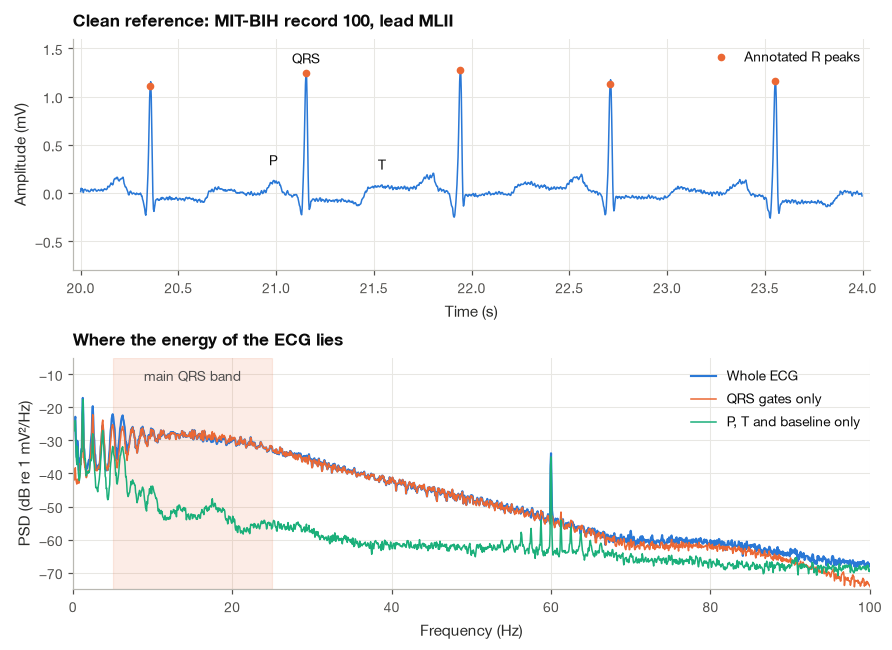

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.8))
ax = axes[0]
show = (t >= 20) & (t < 24)
ax.plot(t[show], s[show], color=C[0], lw=1.0)
rp = r_peaks[(r_peaks >= 20 * fs) & (r_peaks < 24 * fs)]
ax.plot(rp / fs, s[rp], "o", color=C[1], ms=4, label="Annotated R peaks")
r0 = rp[1]
p_idx = r0 - int(0.30 * fs) + np.argmax(s[r0 - int(0.30 * fs):r0 - int(0.10 * fs)])
t_idx = r0 + int(0.15 * fs) + np.argmax(s[r0 + int(0.15 * fs):r0 + int(0.45 * fs)])
for idx, label, dy in [(p_idx, "P", 0.12), (r0, "QRS", 0.10), (t_idx, "T", 0.12)]:
    ax.annotate(label, (idx / fs, s[idx]), xytext=(0, 10 if label != "QRS" else 6),
                textcoords="offset points", ha="center", fontsize=9)
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", ylim=(-0.8, 1.6),
       title="Clean reference: MIT-BIH record 100, lead MLII")
ax.legend(loc="upper right")

ax = axes[1]
ax.axvspan(5, 25, color=C[1], alpha=0.12)
ax.text(15, -12, "main QRS band", ha="center", fontsize=9, color="0.3")
ax.plot(f, 10 * np.log10(S_ecg), color=C[0], lw=1.4, label="Whole ECG")
ax.plot(f, 10 * np.log10(S_qrs), color=C[1], lw=1.0, label="QRS gates only")
ax.plot(f, 10 * np.log10(S_slow), color=C[2], lw=1.0, label="P, T and baseline only")
ax.set(xlim=(0, 100), ylim=(-75, -5), xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV²/Hz)",
       title="Where the energy of the ECG lies")
ax.legend(loc="upper right")
plt.show()

The picture is the one I keep in mind whenever I design an ECG filter. The slow waves and the baseline put almost all their power below about 10 Hz, concentrated in the narrow peaks at the heart rate (about 1.25 Hz here) and its first harmonics. The QRS complexes spread their power over a much wider range, with a broad hump between roughly 5 and 25 Hz and a tail that is still well above the noise floor at 40 Hz and beyond. This tail carries the sharp onset and offset of the QRS and the small notches that cardiologists look for, which is why diagnostic ECG equipment keeps content up to 150 Hz. Any noise that falls inside the 0.5 to 40 Hz range competes directly with the ECG; noise outside it can, at least in principle, be filtered away. One more detail is visible if you look closely: even this "clean" record contains a weak spectral line at exactly 60 Hz, a trace of power-line interference picked up during the original recording. A reference is never perfectly clean, and we will meet this line again in Section 18.4.

(sec-12-1-2)=
## 12.1.2 Signal, Noise and Artifact

The simplest and by far the most common model writes the recorded signal $x[n]$ as the sum of the clean signal $s[n]$ and a disturbance $v[n]$,

(eq-12-1)=
\begin{equation*}
x[n] = s[n] + v[n]. \tag{12.1}
\end{equation*}

Here $x[n]$ is the recording we observe, $s[n]$ is the ECG we want to retain, and $v[n]$ is an added disturbance. At a sample where $s[n]=0.8$ mV and $v[n]=0.2$ mV, the model gives $x[n]=1.0$ mV. In a controlled experiment we know both components; in a patient recording we usually observe only their sum. That is why subtracting a known noise array in a simulation is easier than removing noise from a real ECG.

The words *noise* and *artifact* are often used interchangeably, but I find it helpful to keep a distinction in mind. **Noise** usually refers to random fluctuations without a recognizable shape, such as the thermal noise of an amplifier or the fuzzy activity of many muscle fibers firing asynchronously. An **artifact** is a disturbance with structure and a known origin, such as an electrode pop or a 60 Hz hum. Artifacts are often large and intermittent, and because they have a shape, they can mimic cardiac events.

What counts as noise depends on the question. The respiratory oscillation of the baseline is noise for a cardiologist reading the ST segment, but it is the signal of interest when we estimate the breathing rate from the ECG in Section 22.3. Breathing also affects the ECG in a second way: it rotates the electrical axis of the heart and changes the conductivity of the chest, so the QRS amplitude rises and falls with each breath. This effect is **multiplicative** rather than additive,

(eq-12-2)=
\begin{equation*}
x[n] = s[n]\big(1 + m[n]\big) = s[n] + s[n]\,m[n], \tag{12.2}
\end{equation*}

where $m[n]$ is a slow modulation of a few percent to a few tens of percent. Written in the additive form on the right, the disturbance $s[n]m[n]$ is proportional to the signal: it vanishes on the isoelectric line and is largest at the R peak. By the modulation property of the Fourier transform, its spectrum consists of copies of the ECG spectrum shifted by the respiratory frequency, so it lives in exactly the same bands as the ECG and no linear filter can separate the two. Everything else in this chapter uses the additive model [(12.1)](#eq-12-1).

(sec-12-1-3)=
## 12.1.3 A Field Guide to ECG Noise

For each disturbance I describe its cause, how it looks in the time domain, where it lives in the spectrum, and how large it typically is.

### Baseline wander

**Cause.** Respiration moves the electrodes relative to the heart and changes the thoracic impedance; body movement stretches the skin under the electrodes; and the electrode–skin impedance drifts slowly as the electrolyte gel dries or sweat accumulates. **Look.** A slow, smooth undulation on which the beats ride, sometimes large enough to push the trace off the screen of a monitor. **Spectrum.** Mostly below 0.5 Hz, with the respiratory component at 0.15 to 0.5 Hz (9 to 30 breaths per minute) and movement-related drift that can reach about 1 Hz. **Size.** Tenths of a millivolt at rest, several millivolts during exercise. Baseline wander overlaps the lowest frequencies of the ST segment and T wave, which is what makes its removal delicate ([Section 12.2](02_highpass_baseline_wander.ipynb)).

### Power-line interference

**Cause.** The mains supply runs at 60 Hz in Taiwan and the United States and at 50 Hz in Europe and China. It couples into the recording through *capacitive coupling* between the power wiring and the patient's body or the lead wires, through *magnetic induction* in the loop formed by the lead wires, and through *ground loops* when several earthed devices are connected to the patient. **Look.** A regular, fine oscillation that thickens the trace, most visible on the flat segments between beats. **Spectrum.** A narrow line at the mains frequency, often with weaker harmonics at 120 Hz, 180 Hz and so on; the line wanders by a few tenths of a hertz as the grid load changes. **Size.** From a few microvolts with good electrodes and a well-designed amplifier to a millivolt or more with a loose lead. The theory of notch filters is in Section 15.4 and the applied ECG walkthrough in Section 18.4.

### Muscle (EMG) noise

**Cause.** Contraction of the chest, shoulder or limb muscles near the electrodes adds the summed action potentials of many motor units. **Look.** An irregular, fuzzy band riding on the trace, appearing in bursts when the patient moves or shivers. **Spectrum.** Broadband, from about 10 Hz to several hundred hertz, with most power between 20 and 150 Hz for surface recordings. It overlaps the QRS band, so a low-pass filter can only remove the part above the ECG (Section 18.3). **Size.** Tens of microvolts at rest to about a millivolt during strong contraction.

### Electrode motion artifact

**Cause.** Stretching the skin under an electrode changes the electrochemical potential of the skin and of the electrode–electrolyte interface. **Look.** Irregular deflections lasting a fraction of a second to a few seconds, some of them sharp enough to be mistaken for a QRS complex or a T wave. **Spectrum.** Concentrated between roughly 0.5 and 10 Hz, squarely inside the band of the P and T waves and the lower part of the QRS. **Size.** Up to several millivolts. Electrode motion is the hardest ECG noise to remove because it overlaps the signal both in frequency and in shape, and it is the main source of false alarms in ambulatory monitoring.

### Electrode pop and contact loss

**Cause.** An electrode briefly loses contact with the skin, or a lead is pulled. **Look.** An abrupt step or spike followed by an exponential recovery as the input coupling of the amplifier recharges; with a complete loss of contact, the amplifier output saturates at its supply rail and the trace becomes a flat line. **Spectrum.** Broadband, since a step contains all frequencies with amplitudes falling as $1/f$. **Size.** Often several millivolts, large enough to saturate the amplifier. Pops and saturation are not filtered away but detected and excluded, which is a job for the signal quality indices of Section 18.5.

### Amplifier, thermal and quantization noise

Every resistance $R$ at absolute temperature $T$ generates a random voltage, the thermal (Johnson–Nyquist) noise, with a flat spectrum. Its RMS value over a bandwidth $B$ is

(eq-12-3)=
\begin{equation*}
v_{\text{th}} = \sqrt{4 k T R B}, \tag{12.3}
\end{equation*}

where $k = 1.38 \times 10^{-23}$ J/K is Boltzmann's constant. The input stages of the amplifier add their own white noise and a $1/f$ ("flicker") component that grows at low frequencies. Finally, an analog-to-digital converter with step size $\Delta$ adds an error that behaves like white noise with variance $\Delta^2/12$ ([Section 9.4](../ch09_sampling/index.md)). To judge whether any of this matters for the ECG, we take a body temperature of 310 K, a source resistance of 10 kΩ (wet gel electrode) or 100 kΩ (dry electrode on poorly prepared skin), a 150 Hz diagnostic bandwidth, and the MIT-BIH quantization step of 5 µV (11-bit converter, 200 steps per millivolt).

In [6]:
k_B, T_body, B = 1.380649e-23, 310.0, 150.0     # J/K, K, Hz
for R in (10e3, 100e3):
    v_th = np.sqrt(4 * k_B * T_body * R * B)     # equation (18.3)
    print(f"Thermal noise, R = {R / 1e3:5.0f} kOhm : {v_th * 1e6:.2f} uV RMS")

delta = 1 / 200                                   # mV per ADC step in the MIT-BIH recordings
print(f"Quantization noise, step {delta * 1e3:.0f} uV : {delta / np.sqrt(12) * 1e3:.2f} uV RMS")

Thermal noise, R =    10 kOhm : 0.16 uV RMS
Thermal noise, R =   100 kOhm : 0.51 uV RMS
Quantization noise, step 5 uV : 1.44 uV RMS


Both are a few microvolts at most, several hundred times smaller than a QRS complex of about 1 mV. In clinical ECG they are rarely the limiting factor; they matter for low-resolution wearable converters and for microvolt-level analyses such as late potentials, which need averaging ([Section 10.1](../ch16_noise_removal/index.md)).

### A gallery of simulated artifacts

Before turning to real noise recordings, it helps to see the idealized shapes side by side. We add four artifacts to the clean reference: a 0.15 mV, 60 Hz hum; an electrode pop of 1 mV that decays with a 0.5 s time constant; a 0.3 mV respiratory oscillation at 0.25 Hz (15 breaths per minute); and a two-second burst of muscle noise. For the burst I borrow real muscle noise from the noise stress test database of [Section 12.1.4](#sec-12-1-4), keep only its content above 5 Hz, and shape it with a smooth envelope.

In [7]:
ma_raw = wfdb.rdrecord("../data/nstdb/ma", sampfrom=seg_from, sampto=seg_to, channels=[0]).p_signal[:, 0]
sos_hp5 = signal.butter(4, 5, "highpass", fs=fs, output="sos")
emg_part = signal.sosfiltfilt(sos_hp5, ma_raw)

hum = 0.15 * np.cos(2 * np.pi * 60 * t)
pop = 1.0 * np.exp(-(t - 3.0) / 0.5) * (t >= 3.0)
breathing = 0.3 * np.sin(2 * np.pi * 0.25 * t)
burst_env = np.exp(-0.5 * ((t - 3.5) / 0.5) ** 4)    # flat-topped, about 2 s long
burst = 0.25 / emg_part[:7 * fs].std() * emg_part * burst_env

examples = [("Power-line hum, 60 Hz", hum),
            ("Electrode pop", pop),
            ("Respiratory baseline wander", breathing),
            ("Muscle-noise burst", burst)]

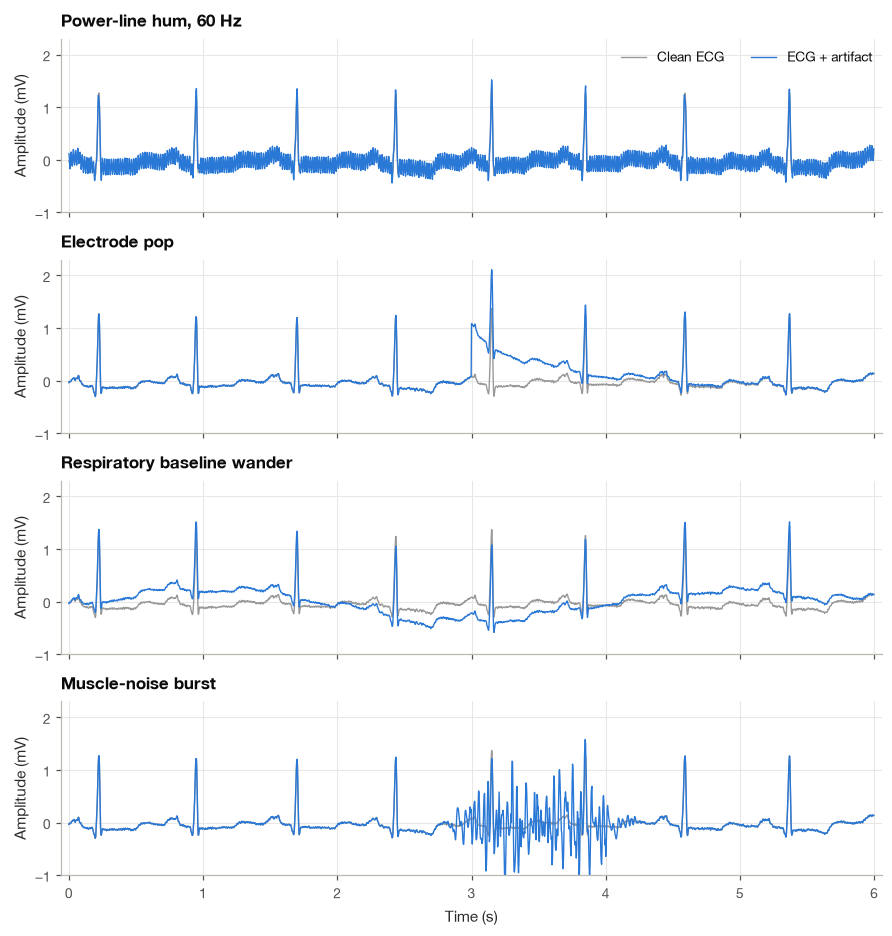

In [8]:
show = t < 6
fig, axes = plt.subplots(4, 1, figsize=(8, 8.4), sharex=True, sharey=True)
for ax, (title, art) in zip(axes, examples):
    ax.plot(t[show], s[show], color="0.6", lw=0.9, label="Clean ECG")
    ax.plot(t[show], s[show] + art[show], color=C[0], lw=0.9, label="ECG + artifact")
    ax.set(title=title, ylabel="Amplitude (mV)")
axes[0].legend(loc="upper right", ncols=2)
axes[0].set_ylim(-1.0, 2.3)
axes[-1].set_xlabel("Time (s)")
plt.show()

Even these idealized examples show why there is no single cure. The hum is a narrow spectral line far above the main ECG energy, the pop and the respiratory wander are slow, and the muscle burst sits right inside the QRS band.

### Aliasing when the anti-aliasing filter is missing

The last entry in the field guide is not a physical noise source but a processing mistake. If a signal contains energy above half the sampling rate when it is sampled, or when it is later downsampled without first being low-pass filtered, that energy folds back into the band below $f_s/2$ ([Section 6.2](../ch09_sampling/index.md)). A component at frequency $f$ reappears at

(eq-12-4)=
\begin{equation*}
f_{\text{alias}} = \left| f - k f_s \right|, \tag{12.4}
\end{equation*}

with the integer $k$ chosen so that $0 \le f_{\text{alias}} \le f_s/2$. Hardware anti-aliasing filters in ECG amplifiers prevent this at acquisition ([Section 11.2](../ch17_ecg/index.md)), but the same error is easy to make in software. Suppose we add the 60 Hz hum and a little muscle noise (25 µV RMS) to the reference and then keep every fourth sample to obtain a 90 Hz signal. A 60 Hz hum then lands at $|60 - 90| = 30$ Hz, right in the QRS band, where no later filter can tell it apart from the ECG. We compare naive downsampling (`x[::4]`) with `scipy.signal.decimate`, which applies a low-pass filter before discarding samples.

In [9]:
x_hum = s + hum + 0.025 * emg_part / emg_part.std()     # hum plus 25 uV RMS of muscle noise
fs_low = fs / 4
x_naive = x_hum[::4]
x_proper = signal.decimate(x_hum, 4, ftype="fir", zero_phase=True)

f_low, S_naive = welch_psd(x_naive, fs_low)
_, S_proper = welch_psd(x_proper, fs_low)
_, S_ref = welch_psd(s[::4], fs_low)                 # clean ECG has almost nothing above 45 Hz

k30 = np.argmin(np.abs(f_low - 30))
print(f"PSD at 30 Hz, naive downsampling : {10 * np.log10(S_naive[k30]):6.1f} dB")
print(f"PSD at 30 Hz, decimate()         : {10 * np.log10(S_proper[k30]):6.1f} dB")
print(f"PSD at 30 Hz, clean ECG          : {10 * np.log10(S_ref[k30]):6.1f} dB")

PSD at 30 Hz, naive downsampling :   -9.1 dB
PSD at 30 Hz, decimate()         :  -34.0 dB
PSD at 30 Hz, clean ECG          :  -32.0 dB


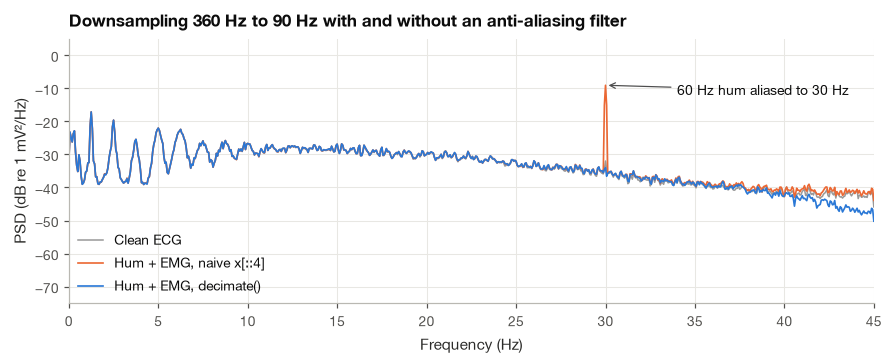

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(f_low, 10 * np.log10(S_ref), color="0.6", lw=1.0, label="Clean ECG")
ax.plot(f_low, 10 * np.log10(S_naive), color=C[1], lw=1.1, label="Hum + EMG, naive x[::4]")
ax.plot(f_low, 10 * np.log10(S_proper), color=C[0], lw=1.1, label="Hum + EMG, decimate()")
ax.annotate("60 Hz hum aliased to 30 Hz", (30, 10 * np.log10(S_naive[k30])), xytext=(34, -12),
            arrowprops=dict(arrowstyle="->", color="0.3"), fontsize=9)
ax.set(xlim=(0, 45), ylim=(-75, 5), xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV²/Hz)",
       title="Downsampling 360 Hz to 90 Hz with and without an anti-aliasing filter")
ax.legend(loc="lower left")
plt.show()

The naive version shows a spectral line at 30 Hz about 25 dB above the ECG spectrum, and above about 35 Hz its floor is a few decibels higher because muscle noise from above 45 Hz has folded down as well. The properly decimated signal has neither (its slight drop near 45 Hz is the transition band of the anti-aliasing filter). Once aliasing has happened, it cannot be undone.

(sec-12-1-4)=
## 12.1.4 Real Noise from the MIT-BIH Noise Stress Test Database

Simulated artifacts are useful for intuition, but a denoising method should be tested on the real thing. The MIT-BIH Noise Stress Test Database {cite:p}`moody1984,goldberger2000` provides it. Its authors recorded physically active volunteers with standard ambulatory ECG equipment, placing the electrodes on the limbs in positions where the subjects' own ECG was not visible. What remained was noise alone, in three half-hour, two-channel records:

- `bw`: **baseline wander**, dominated by slow drift from respiration and body movement;
- `em`: **electrode motion artifact**, which also contains some baseline wander and muscle noise;
- `ma`: **muscle artifact**, recorded during muscle activity.

### Step 4: Load the three noise records

All three are sampled at 360 Hz, the same rate as the MIT-BIH Arrhythmia Database, so they can be added directly to its ECG records. We load channel `noise1` of each record over the same five-minute window as the ECG and remove each record's small mean.

In [11]:
noise = {}
for name in ("bw", "em", "ma"):
    rec_n = wfdb.rdrecord(f"../data/nstdb/{name}", sampfrom=seg_from, sampto=seg_to, channels=[0])
    noise[name] = rec_n.p_signal[:, 0] - rec_n.p_signal[:, 0].mean()

summary = pd.DataFrame({name: {"RMS (mV)": np.sqrt(np.mean(v ** 2)),
                               "peak-to-peak (mV)": np.ptp(v)} for name, v in noise.items()}).T
summary.loc["ECG (record 100)"] = [np.sqrt(np.mean(s ** 2)), np.ptp(s)]
print(summary.round(3))

                  RMS (mV)  peak-to-peak (mV)
bw                   0.482              3.860
em                   0.702              5.545
ma                   0.176              2.310
ECG (record 100)     0.195              1.990


As recorded, the baseline-wander and electrode-motion records are much larger than the ECG we are going to add them to, and the muscle record is about as large. The time plots below use a common vertical scale so that sizes can be compared directly.

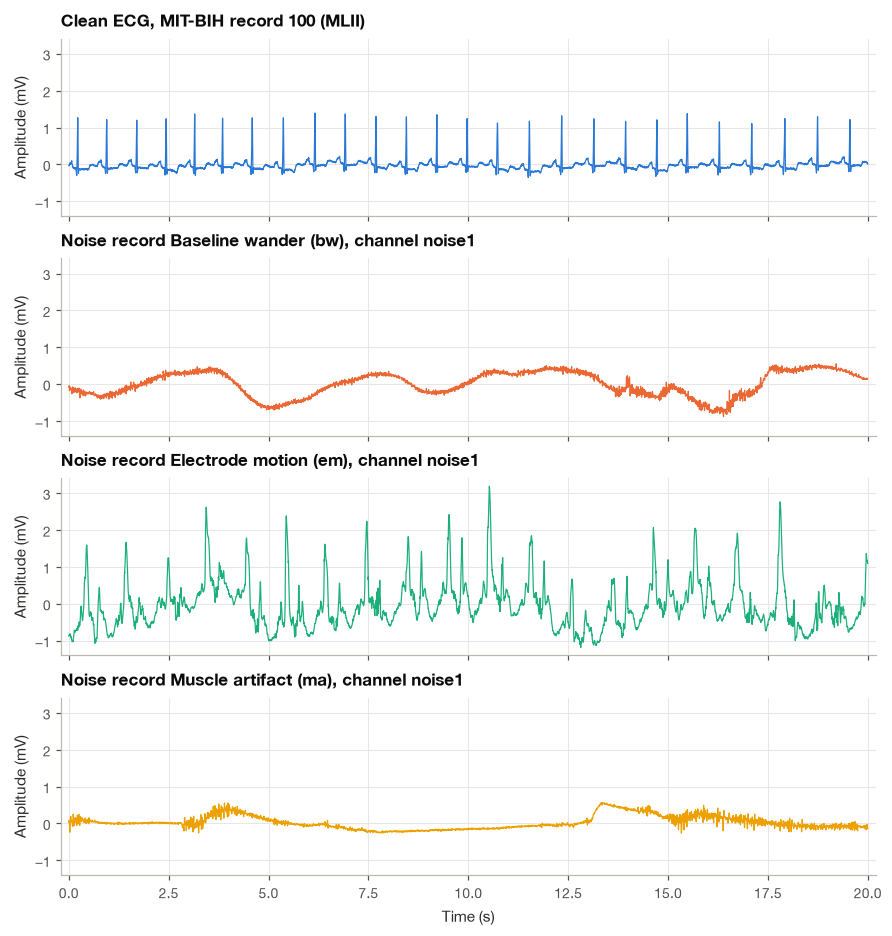

In [12]:
show = t < 20
labels = {"bw": "Baseline wander (bw)", "em": "Electrode motion (em)", "ma": "Muscle artifact (ma)"}
fig, axes = plt.subplots(4, 1, figsize=(8, 8.4), sharex=True, sharey=True)
axes[0].plot(t[show], s[show], color=C[0], lw=0.8)
axes[0].set(title="Clean ECG, MIT-BIH record 100 (MLII)", ylabel="Amplitude (mV)")
for ax, (name, v), color in zip(axes[1:], noise.items(), (C[1], C[2], C[3])):
    ax.plot(t[show], v[show], color=color, lw=0.8)
    ax.set(title=f"Noise record {labels[name]}, channel noise1", ylabel="Amplitude (mV)")
axes[-1].set_xlabel("Time (s)")
plt.show()

The three records have very different personalities. Baseline wander is a slow, smooth undulation with a period of several seconds. The muscle record combines a slow drift with a rapid, irregular fuzz. Electrode motion is the most worrying: irregular deflections lasting a fraction of a second to a second or two, some of them sharp enough to be read as a beat. A QRS detector that sees such a deflection reports an extra beat, which is why electrode motion is regarded as the most troublesome of the three {cite:p}`moody1984`.

(sec-12-1-5)=
## 12.1.5 Where the Noise Lives in Frequency

### Step 5: Overlay the noise spectra on the ECG spectrum

The time plots suggest that the three noises differ mainly in speed, so we compare their PSDs with that of the ECG. To compare *shapes* rather than sizes, each noise is first scaled to the same power as the ECG. We also tabulate the share of each signal's power in five bands.

In [13]:
P_s = np.mean(s ** 2)                                  # s already has zero mean
psd = {name: welch_psd(v * np.sqrt(P_s / np.mean(v ** 2)), fs)[1] for name, v in noise.items()}

bands = [(0, 0.5), (0.5, 5), (5, 15), (15, 40), (40, fs / 2 + 1)]
band_names = ["< 0.5 Hz", "0.5–5 Hz", "5–15 Hz", "15–40 Hz", "> 40 Hz"]


def band_percent(S):
    """Percentage of total PSD power falling in each band."""
    return [100 * S[(f >= lo) & (f < hi)].sum() / S.sum() for lo, hi in bands]


table = pd.DataFrame([band_percent(S_ecg)] + [band_percent(S) for S in psd.values()],
                     index=["ECG"] + list(psd), columns=band_names)
print("Share of total power in each band (%)")
print(table.round(1))

Share of total power in each band (%)
     < 0.5 Hz  0.5–5 Hz  5–15 Hz  15–40 Hz  > 40 Hz
ECG       3.7      17.0     43.0      34.9      1.4
bw       99.1       0.8      0.0       0.1      0.0
em       38.2      53.4      7.6       0.7      0.1
ma       79.8      10.9      1.0       6.7      1.5


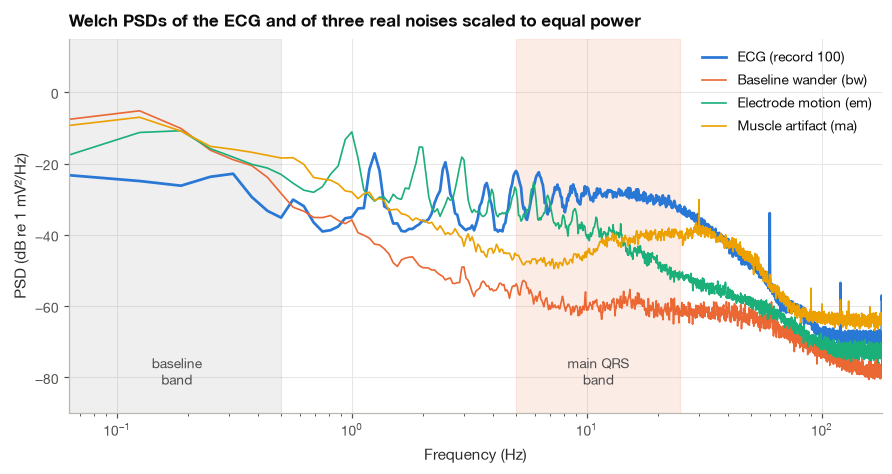

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axvspan(0.0625, 0.5, color="0.5", alpha=0.12)
ax.axvspan(5, 25, color=C[1], alpha=0.12)
ax.text(0.18, -82, "baseline\nband", ha="center", fontsize=9, color="0.3")
ax.text(11.2, -82, "main QRS\nband", ha="center", fontsize=9, color="0.3")
ax.semilogx(f[1:], 10 * np.log10(S_ecg[1:]), color=C[0], lw=1.8, label="ECG (record 100)")
for (name, S), color in zip(psd.items(), (C[1], C[2], C[3])):
    ax.semilogx(f[1:], 10 * np.log10(S[1:]), color=color, lw=1.1, label=labels[name])
ax.set(xlim=(0.0625, 180), ylim=(-90, 15), xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV²/Hz)",
       title="Welch PSDs of the ECG and of three real noises scaled to equal power")
ax.legend(loc="upper right")
plt.show()

The ECG has its peaks at the heart rate and its harmonics, with 60 % of its power between 0.5 and 15 Hz and most of the rest between 15 and 40 Hz. Against it, each noise tells a clear story.

- **Baseline wander** keeps 99 % of its power below 0.5 Hz, where the ECG has only a few percent. The two spectra barely overlap, so a high-pass filter can separate them; the art is in doing so without damaging the ST segment ([Section 12.2](02_highpass_baseline_wander.ipynb)).
- **Muscle artifact** in this database is not pure EMG. About 80 % of its power is slow drift below 0.5 Hz, which a high-pass filter removes, but a broad plateau of muscle activity extends from a few hertz to well beyond 40 Hz, right across the QRS band. A low-pass filter can trim the part above the ECG band, but whatever falls between 5 and 40 Hz stays (Section 18.3).
- **Electrode motion** puts more than half of its power between 0.5 and 5 Hz and a further 8 % between 5 and 15 Hz. This is exactly where the P and T waves, the heart-rate fundamental and much of the QRS live. No fixed frequency-selective filter can remove it without removing the ECG along with it.

This is the frequency-domain reason why electrode motion is the hardest artifact: its spectrum overlaps the signal's spectrum almost completely, and it also resembles the signal in the time domain. The methods that help against it use extra information, such as a reference sensor ([Section 16.3](../ch16_noise_removal/index.md)) or the repetitive nature of the heartbeat ([Section 10.1](../ch16_noise_removal/index.md)), or they simply detect the corrupted stretches and set them aside (Section 18.5).

(sec-12-1-6)=
## 12.1.6 Building Noisy Test Signals at a Chosen SNR

To evaluate a denoising method quantitatively we need two things that never exist together in a real recording: the noisy signal and the clean signal underneath it. The noise stress test approach creates them artificially. We take the clean ECG $s[n]$, scale a real noise record $v[n]$ by a gain $g$, and add the two,

$$
x[n] = s[n] + g\,v[n].
$$

The gain is chosen to produce a desired signal-to-noise ratio. We define the powers of the signal and of the noise over the $N$ samples of the test segment as

(eq-12-5)=
\begin{equation*}
P_s = \frac{1}{N}\sum_{n=0}^{N-1}\big(s[n] - \bar{s}\big)^2, \qquad
P_v = \frac{1}{N}\sum_{n=0}^{N-1} v[n]^2, \qquad
\mathrm{SNR}_{\text{in}} = 10\log_{10}\frac{P_s}{P_v}\ \text{dB}, \tag{12.5}
\end{equation*}

where $\bar{s}$ is the mean of $s$ and the noise is taken to have zero mean. The signal mean is removed because an ECG offset of a few tenths of a millivolt (record 100 sits at about $-0.31$ mV) would otherwise inflate $P_s$ without containing any cardiac information. This is the power ratio of Section 3.4.

**Deriving the gain.** After scaling, the noise power becomes $\frac{1}{N}\sum (g\,v[n])^2 = g^2 P_v$. We want

$$
10\log_{10}\frac{P_s}{g^2 P_v} = \mathrm{SNR}.
$$

Dividing both sides by 10 and raising 10 to the power of each side removes the logarithm,

$$
\frac{P_s}{g^2 P_v} = 10^{\mathrm{SNR}/10}.
$$

Solving for $g^2$ and taking the positive square root gives

(eq-12-6)=
\begin{equation*}
g = \sqrt{\frac{P_s}{P_v\,10^{\mathrm{SNR}/10}}}. \tag{12.6}
\end{equation*}

Every 6 dB reduction in SNR roughly doubles the noise amplitude, because $10^{6/20} \approx 2$.

```{note}
The SNR defined here is a plain power ratio over the whole segment. The test records distributed with the noise stress test database were built with a different definition based on measured QRS amplitudes, so an "SNR of 6 dB" in this book is not numerically the same as the 6 dB label of an nstdb record. What matters is that we use one definition consistently.
```

### Step 6: Write a function that adds noise at a chosen SNR

In [15]:
def add_noise_at_snr(s, v, snr_db):
    """Return s + g*v with g from equation (18.6), so that the SNR of (18.5) equals snr_db."""
    P_s = np.mean((s - s.mean()) ** 2)
    v = v - v.mean()
    g = np.sqrt(P_s / (np.mean(v ** 2) * 10 ** (snr_db / 10)))
    return s + g * v


def snr_db(s, v):
    """Power SNR of equation (18.5) in dB."""
    return 10 * np.log10(np.mean((s - s.mean()) ** 2) / np.mean((v - v.mean()) ** 2))


snr_levels = [24, 12, 6, 0]
noisy_em = {snr: add_noise_at_snr(s, noise["em"], snr) for snr in snr_levels}
for snr, x in noisy_em.items():
    print(f"target {snr:3d} dB -> measured {snr_db(s, x - s):6.2f} dB, "
          f"noise RMS {np.sqrt(np.mean((x - s) ** 2)):.3f} mV")

target  24 dB -> measured  24.00 dB, noise RMS 0.012 mV
target  12 dB -> measured  12.00 dB, noise RMS 0.049 mV
target   6 dB -> measured   6.00 dB, noise RMS 0.097 mV
target   0 dB -> measured  -0.00 dB, noise RMS 0.195 mV


### Step 7: Look at the result

The measured SNR matches the target exactly. The figure shows the same eight seconds of record 100 with electrode-motion noise at the four levels. At 24 dB the noise is barely visible, at 12 dB it begins to disturb the P and T waves, at 6 dB some deflections are as large as T waves, and at 0 dB the noise has the same power as the ECG and several deflections could be read as beats.

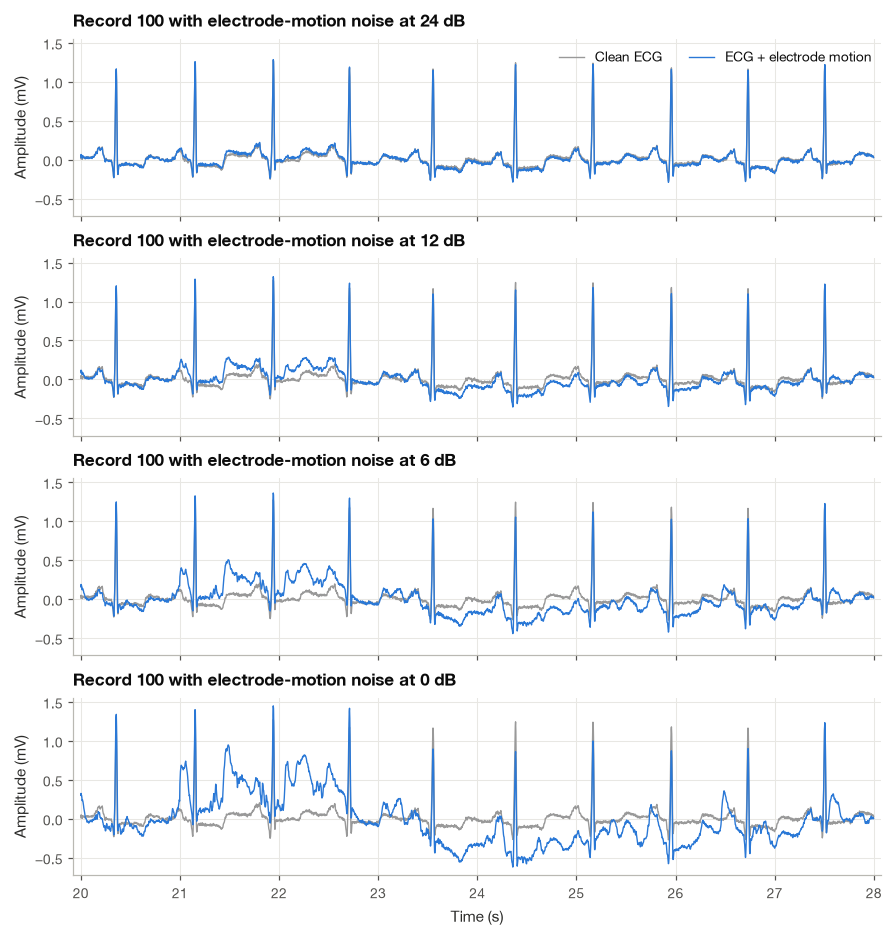

In [16]:
show = (t >= 20) & (t < 28)
fig, axes = plt.subplots(4, 1, figsize=(8, 8.4), sharex=True, sharey=True)
for ax, snr in zip(axes, snr_levels):
    ax.plot(t[show], s[show], color="0.6", lw=0.9, label="Clean ECG")
    ax.plot(t[show], noisy_em[snr][show], color=C[0], lw=0.9, label="ECG + electrode motion")
    ax.set(title=f"Record 100 with electrode-motion noise at {snr} dB", ylabel="Amplitude (mV)")
axes[0].legend(loc="upper right", ncols=2)
axes[-1].set_xlabel("Time (s)")
plt.show()

### Step 8: Compare with a naturally noisy recording

Synthetic test signals are only useful if they resemble real recordings. Record 105 of the MIT-BIH Arrhythmia Database is described in its header as dominated by "high-grade noise and artifact", and its annotators marked nearly ninety changes in signal quality (the `~` annotations). We plot a quiet and a noisy ten-second stretch of it with the annotated beats.

In [17]:
rec105 = wfdb.rdrecord("../data/mitdb/105", channels=[0])
ann105 = wfdb.rdann("../data/mitdb/105", "atr")
x105 = rec105.p_signal[:, 0]
n_quality = sum(sym == "~" for sym in ann105.symbol)
n_beats = sum(sym in ("N", "V", "A", "Q") for sym in ann105.symbol)
print(f"Record 105: {n_beats} beat annotations, {n_quality} signal-quality changes ('~')")

Record 105: 2572 beat annotations, 88 signal-quality changes ('~')


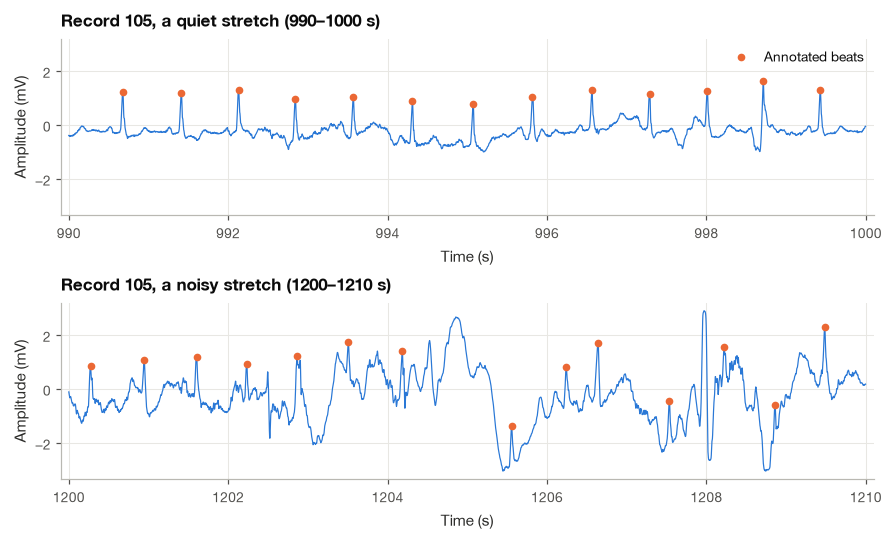

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.8), sharey=True)
beats105 = ann105.sample[np.isin(ann105.symbol, ["N", "V", "A", "Q"])]
for ax, start, title in [(axes[0], 990, "Record 105, a quiet stretch (990–1000 s)"),
                         (axes[1], 1200, "Record 105, a noisy stretch (1200–1210 s)")]:
    sl = slice(start * fs, (start + 10) * fs)
    tt = np.arange(sl.start, sl.stop) / fs
    ax.plot(tt, x105[sl], color=C[0], lw=0.8)
    b = beats105[(beats105 >= sl.start) & (beats105 < sl.stop)]
    ax.plot(b / fs, x105[b], "o", color=C[1], ms=4, label="Annotated beats")
    ax.set(title=title, xlabel="Time (s)", ylabel="Amplitude (mV)")
axes[0].legend(loc="upper right")
plt.show()

The noisy stretch combines much of what we have seen: a baseline that swings by several millivolts, sharp deflections near 1205 s and 1208 s that look like beats but are not, and true beats whose apparent amplitude and polarity change because they ride on the artifact. The real record is harder than any single synthetic noise, because the noises occur together and change over time. I use record 105 in Section 18.5 to test a complete preprocessing pipeline and to flag the stretches that no filter can rescue.

(sec-12-1-7)=
## 12.1.7 Measuring Success: Quality Metrics

Suppose a denoising method turns the noisy signal $x[n]$ into an estimate $\hat{s}[n]$. How close is $\hat{s}$ to $s$? Several numbers are in common use, and it pays to define them precisely because papers do not always agree on the details. All of them are built from the error $e[n] = \hat{s}[n] - s[n]$, and every section of this chapter reports them.

**Output SNR and SNR improvement.** Treating the error as the noise that remains after processing,

(eq-12-7)=
\begin{equation*}
\mathrm{SNR}_{\text{out}} = 10\log_{10}\frac{P_s}{\frac{1}{N}\sum_n \big(\hat{s}[n] - s[n]\big)^2}, \qquad
\Delta\mathrm{SNR} = \mathrm{SNR}_{\text{out}} - \mathrm{SNR}_{\text{in}}\ \text{dB}. \tag{12.7}
\end{equation*}

The improvement $\Delta\mathrm{SNR}$ is the most useful single number for comparing methods across noise levels: a value of 10 dB means the method reduced the error power tenfold. The error contains both the noise left behind and any distortion of the signal itself, so a filter that removes the noise but also flattens the QRS is penalized.

**Root-mean-square error**, in the units of the signal (mV for the ECG),

(eq-12-8)=
\begin{equation*}
\mathrm{RMSE} = \sqrt{\frac{1}{N}\sum_{n}\big(\hat{s}[n] - s[n]\big)^2}. \tag{12.8}
\end{equation*}

**Percentage root-mean-square difference**, a normalized error popular in ECG compression and denoising,

(eq-12-9)=
\begin{equation*}
\mathrm{PRD} = 100\sqrt{\frac{\sum_n \big(\hat{s}[n] - s[n]\big)^2}{\sum_n \big(s[n] - \bar{s}\big)^2}}\ \%. \tag{12.9}
\end{equation*}

I subtract the mean in the denominator, a form sometimes called the normalized PRD (PRDN). The original PRD divides by $\sum s[n]^2$, which for an ECG with a large DC offset makes the error look much smaller than it is and makes the result depend on an arbitrary electrode potential.

**Correlation coefficient** between estimate and reference,

(eq-12-10)=
\begin{equation*}
\rho = \frac{\sum_n (\hat{s}[n] - \bar{\hat{s}})(s[n] - \bar{s})}
{\sqrt{\sum_n (\hat{s}[n] - \bar{\hat{s}})^2}\sqrt{\sum_n (s[n] - \bar{s})^2}}. \tag{12.10}
\end{equation*}

### How the metrics are related

The first three metrics are not independent. Squaring the PRD and dividing the numerator and denominator of [(12.9)](#eq-12-9) by $N$,

$$
\begin{aligned}
\left(\frac{\mathrm{PRD}}{100}\right)^2 &= \frac{\frac{1}{N}\sum_n e[n]^2}{\frac{1}{N}\sum_n (s[n] - \bar{s})^2}
= \frac{\mathrm{RMSE}^2}{P_s} \\
&= 10^{-\mathrm{SNR}_{\text{out}}/10},
\end{aligned}
$$

where the last line uses definition [(12.7)](#eq-12-7), which says $P_s / \mathrm{RMSE}^2 = 10^{\mathrm{SNR}_{\text{out}}/10}$. Taking square roots,

(eq-12-11)=
\begin{equation*}
\mathrm{PRD} = 100 \cdot 10^{-\mathrm{SNR}_{\text{out}}/20}\ \%, \qquad
\mathrm{RMSE} = \sqrt{P_s}\cdot 10^{-\mathrm{SNR}_{\text{out}}/20}. \tag{12.11}
\end{equation*}

So for a fixed test signal, output SNR, RMSE and PRD carry the same information on different scales: an output SNR of 20 dB is a PRD of 10 %, and 0 dB is a PRD of 100 %. The correlation coefficient is different in kind. It ignores any gain or offset, because $\rho(a\hat{s} + b, s) = \rho(\hat{s}, s)$ for every $a > 0$, so it measures whether the *shape* is right but not whether the *size* is right. A method that halves the amplitude of every wave would achieve $\rho = 1$ and still be clinically useless, since ST deviations and QRS amplitudes would be wrong by a factor of two.

### Step 9: Implement the metrics and check equation (12.11)

We check [(12.11)](#eq-12-11) and illustrate the blind spot of $\rho$ with three estimates for the reference corrupted by muscle noise at 12 dB: the noisy signal itself, a zero-phase 40 Hz low-pass filtered version of it, and a "perfectly shaped" estimate that is simply half the clean ECG.

In [19]:
def quality(s_hat, s, x=None):
    """SNR_out, Delta SNR (if x given), RMSE, PRD and correlation, equations (18.7)-(18.10)."""
    e = s_hat - s
    P_s = np.mean((s - s.mean()) ** 2)
    out = {"SNR_out (dB)": 10 * np.log10(P_s / np.mean(e ** 2))}
    if x is not None:
        out["dSNR (dB)"] = out["SNR_out (dB)"] - snr_db(s, x - s)
    out["RMSE (mV)"] = np.sqrt(np.mean(e ** 2))
    out["PRD (%)"] = 100 * np.sqrt(np.sum(e ** 2) / np.sum((s - s.mean()) ** 2))
    out["rho"] = np.corrcoef(s_hat, s)[0, 1]
    return out


x_ma = add_noise_at_snr(s, noise["ma"], 12)
sos_lp40 = signal.butter(4, 40, "lowpass", fs=fs, output="sos")
candidates = {"noisy x (no processing)": x_ma,
              "40 Hz zero-phase low-pass": signal.sosfiltfilt(sos_lp40, x_ma),
              "0.5 * clean ECG": 0.5 * s}
results = pd.DataFrame({name: quality(est, s, x_ma) for name, est in candidates.items()}).T
print(results.round(3))

q = results.loc["noisy x (no processing)"]
print(f"\nCheck (18.11): 100*10^(-SNR_out/20) = {100 * 10 ** (-q['SNR_out (dB)'] / 20):.3f} %, "
      f"PRD = {q['PRD (%)']:.3f} %")

                           SNR_out (dB)  dSNR (dB)  RMSE (mV)  PRD (%)    rho
noisy x (no processing)          12.000      0.000      0.049   25.119  0.970
40 Hz zero-phase low-pass        11.427     -0.573      0.052   26.831  0.965
0.5 * clean ECG                   6.021     -5.979      0.097   50.000  1.000

Check (18.11): 100*10^(-SNR_out/20) = 25.119 %, PRD = 25.119 %


For the unprocessed signal the output SNR equals the input SNR of 12 dB, so $\Delta\mathrm{SNR} = 0$ and the PRD is $100 \cdot 10^{-12/20} \approx 25\%$, exactly as [(12.11)](#eq-12-11) predicts. The 40 Hz low-pass actually makes things slightly worse ($\Delta\mathrm{SNR} \approx -0.6$ dB): most of this noise record's power is slow drift that a low-pass filter leaves untouched, and the little it removes above 40 Hz is outweighed by the small distortion it causes on the sharp QRS complexes. The halved ECG has a correlation of exactly 1 and yet the worst error of the three, with a PRD of 50 %. In the rest of the chapter I therefore always report an error-based metric (ΔSNR, RMSE or PRD) and use $\rho$ only as a complement. For baseline removal we will add one clinically motivated metric, the error in the ST level, in [Section 12.2](02_highpass_baseline_wander.ipynb).

(sec-12-1-8)=
## 12.1.8 A Map of Noises and Remedies

The table collects the field guide in one place. The frequency ranges are typical values, not sharp limits, and the last column points to where each remedy is developed.

| Noise | Typical frequency range | Typical size | Main remedy | Where |
|---|---|---|---|---|
| Baseline wander | below 0.5 Hz (up to about 1 Hz with movement) | 0.1 to several mV | high-pass filter, median or spline baseline | [Section 12.2](02_highpass_baseline_wander.ipynb) |
| Muscle (EMG) noise | about 10 Hz to several hundred Hz | 0.01 to 1 mV | low-pass filter above the QRS band; wavelets or averaging in band | Section 18.3, [Section 14.2](../ch24_wavelets/index.md) |
| Power-line interference | 50 or 60 Hz and harmonics | µV to mV | notch or comb filter, adaptive canceller | Section 18.4, Section 15.4 |
| Electrode motion | about 0.5 to 10 Hz, irregular | up to several mV | reference-based adaptive filtering, averaging, quality-based rejection | [Section 16.3](../ch16_noise_removal/index.md), Section 18.5 |
| Electrode pop, contact loss | broadband steps, saturation | several mV | detection and exclusion | Section 18.5 |
| Thermal, amplifier, quantization | white (plus $1/f$) | a few µV | good electrodes and converter; averaging | [Section 9.4](../ch09_sampling/index.md), [Section 10.1](../ch16_noise_removal/index.md) |
| Aliasing | anything above $f_s/2$, folded down | any | anti-aliasing filter before sampling or downsampling | [Section 11.2](../ch17_ecg/index.md), [Section 6.2](../ch09_sampling/index.md) |

## Summary

A clean ECG puts most of the power of its P and T waves below about 10 Hz and spreads the power of the QRS complexes over roughly 5 to 25 Hz, with a tail that still matters at 40 Hz and beyond. Every ECG filter is a compromise between this spectrum and that of the noise. Baseline wander lives almost entirely below 0.5 Hz and power-line interference in narrow lines at 50 or 60 Hz and their harmonics, so both can be separated from the ECG in frequency. Muscle noise overlaps the QRS band and can only be trimmed, electrode motion overlaps the whole ECG band and resembles the signal in shape, and electrode pops and saturation must be detected rather than filtered. Thermal and quantization noise are microvolt-level and rarely matter, while aliasing is a processing error that cannot be undone after the fact.

To compare methods fairly, we add real noise from the MIT-BIH Noise Stress Test Database to a clean stretch of record 100 at a controlled power SNR, using the gain of equation [(12.6)](#eq-12-6), and judge the result with ΔSNR, RMSE, PRD and the correlation coefficient. For a fixed test signal the first three are equivalent through equation [(12.11)](#eq-12-11), while the correlation is blind to gain errors. The next four sections use this machinery to remove baseline wander, muscle noise and power-line interference, and then combine the pieces into a complete preprocessing pipeline with signal quality checks.

## Exercises

1. Show that the correlation coefficient [(12.10)](#eq-12-10) is unchanged when $\hat{s}$ is replaced by $a\hat{s} + b$ with $a > 0$. What happens when $a < 0$? Give an example of a denoising failure that $\rho$ would detect and one that it would miss.
2. Using equation [(12.11)](#eq-12-11), express RMSE in terms of PRD and $P_s$. For our reference segment of record 100, what RMSE corresponds to a PRD of 9 %?
3. An ECG is sampled at 500 Hz in a country with 50 Hz mains, and then downsampled by keeping every fifth sample. Where do the 50 Hz line and its harmonics at 100, 150 and 200 Hz land after downsampling? Use equation [(12.4)](#eq-12-4) and check your answer with a simulated signal.
4. Repeat the band-power analysis of [Section 12.1.5](#sec-12-1-5) for channel `noise2` of each noise record. Are the conclusions the same? Which channel would you choose to construct a test set, and why?
5. Corrupt the reference with each of the three nstdb noises at 6 dB and apply a zero-phase 0.5–40 Hz Butterworth band-pass filter (`signal.butter(2, [0.5, 40], "bandpass", fs=fs, output="sos")` with `sosfiltfilt`). Compute ΔSNR for each noise and explain the ranking with the spectra of Section 12.1.5.
6. Simulate an ECG with 20 % respiratory amplitude modulation at 0.3 Hz, equation [(12.2)](#eq-12-2). Compute its PSD and locate the sidebands around the heart-rate harmonics. Then estimate the beat-by-beat R-peak amplitude using the annotations, and remove the modulation by dividing each beat by its smoothed amplitude. How much of the multiplicative disturbance can you remove?

## Further Reading

The noise stress test methodology and the database used throughout this chapter are described by {cite:t}`moody1984`, and the PhysioNet resource that distributes it by {cite:t}`goldberger2000`. {cite:t}`sornmo2005` give a careful account of ECG noise sources and their spectra, and {cite:t}`clifford2006` discusses noise and signal quality in ambulatory ECG analysis. The physical origins of electrode, motion and interference noise are treated in depth by {cite:t}`webster2010`, and {cite:t}`rangayyan2015` (Chapter 3) surveys artifacts in many biomedical signals with clinical examples.